<a href="https://colab.research.google.com/github/RodrigoMesel/RNA-e-Deep-Learning---CESAR-School-2026.01-A/blob/main/2.2/2.2_regressao_linear_numpy.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<a href="https://colab.research.google.com/github/vcasadei/Redes-Neurais-CESAR-School/blob/2026.01-A/2%20-%20Regress%C3%A3o%20Linear/2.2_regressao_linear_numpy.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Abrir no Colab"/></a>

# 2.2 — Regressão Linear com NumPy

## Objetivos

- Estimar o comprimento das pétalas da íris a partir do comprimento das sépalas com regressão linear.
- Implementar tudo em NumPy, de forma explícita: o modelo (uma classe com uma camada), a predição, a função de custo (loss), o cálculo do gradiente e a atualização dos parâmetros.
- Escrever a predição de várias amostras de uma vez na forma matricial e acompanhar os shapes.
- Comparar o resultado do gradiente descendente com a solução analítica.

É o mesmo problema do notebook 2.1, agora sem caixas-pretas: cada passo do diagrama abaixo vira uma linha de código.

![Otimização](https://raw.githubusercontent.com/vcasadei/images/master/RegressaoLinear_Otimizacao.png)

No diagrama, $N$ é o número de amostras, que neste notebook chamamos de $M$.

## Importação das bibliotecas

In [26]:
import matplotlib.pyplot as plt          # gráficos
import numpy as np                       # processamento matricial
from sklearn.datasets import load_iris  # para carregar o dataset

np.random.seed(1234)

## Dados

### Leitura dos dados

In [27]:
iris = load_iris()
data = iris.data[iris.target == 1, ::2]  # versicolor; colunas 0 e 2: comprimento das sépalas e das pétalas

x_train = data[:, 0:1]
y_train = data[:, 1:2]

n_samples = x_train.shape[0]
print('x_train.shape:', x_train.shape, x_train.dtype)
print('y_train.shape:', y_train.shape, y_train.dtype)

print('x_train[:5]:\n', x_train[:5])
print('y_train[:5]:\n', y_train[:5])

x_train.shape: (50, 1) float64
y_train.shape: (50, 1) float64
x_train[:5]:
 [[7. ]
 [6.4]
 [6.9]
 [5.5]
 [6.5]]
y_train[:5]:
 [[4.7]
 [4.5]
 [4.9]
 [4. ]
 [4.6]]


### Normalização dos dados

Normalização min-max para o intervalo $[0, 1]$: $x \leftarrow \dfrac{x - \min(x)}{\max(x) - \min(x)}$, e o mesmo para $y$.

In [28]:
x_train -= x_train.min()
x_train /= x_train.max()   # após subtrair o mínimo, o máximo vale max - min
y_train -= y_train.min()
y_train /= y_train.max()

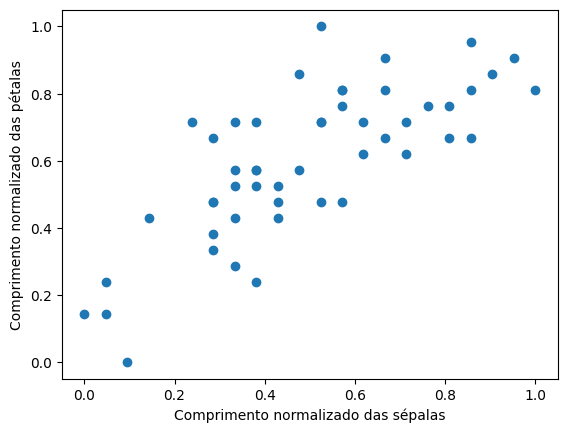

In [29]:
plt.scatter(x_train, y_train)
plt.xlabel('Comprimento normalizado das sépalas')
plt.ylabel('Comprimento normalizado das pétalas')
plt.show()

## Modelo

### Reta de ajuste

A equação da reta no plano precisa de dois parâmetros: a interseção $w_0$ (*bias*) e a inclinação $w_1$.

![Reta](https://raw.githubusercontent.com/vcasadei/images/master/linhareta.png)

A reta de ajuste será dada por:

$$ \hat{y} = w_0 + w_1 x $$

onde
- $x$ é a variável de entrada (comprimento das sépalas);
- $\hat{y}$ é a predição (comprimento estimado das pétalas);
- $w_1$ é o coeficiente angular da reta (peso);
- $w_0$ é o valor de $\hat{y}$ quando $x = 0$ (interseção com o eixo vertical), chamado de *bias*.

Nos slides, a mesma reta aparece como $h_\theta(x) = \theta_0 + \theta_1 x$: $w_0 = \theta_0$ (bias), $w_1 = \theta_1$ (peso) e $\hat{y} = h_\theta(x)$.

### Modelo de regressão linear como neurônio

![Neurônio](https://raw.githubusercontent.com/vcasadei/images/master/RegressaoLinearNeuronio.png)

### Formulação matricial do neurônio

- $\mathbf{w} = [w_0 \ \ w_1]$ é o vetor linha de parâmetros, shape $(1, 2)$;
- $\mathbf{x} = [1 \ \ x_0]$ é o vetor linha de uma amostra, com o 1 do *bias*, shape $(1, 2)$. Aqui $x_0$ é o (único) atributo de entrada, o comprimento da sépala.

$$ \hat{y} = 1 \cdot w_0 + x_0 \cdot w_1 $$

$$ [\hat{y}] = [1 \ \ x_0] \begin{bmatrix} w_0 \\ w_1 \end{bmatrix} $$

$$ \hat{y} = \mathbf{x} \mathbf{w}^T $$

### Predição de várias amostras

Empilhando as $M$ amostras, uma por linha, obtemos a matriz $\mathbf{X}$ de shape $(M, 2)$. A predição de todas as amostras é um único produto de matrizes, $\hat{\mathbf{y}} = \mathbf{X} \mathbf{w}^T$:

$$
\begin{bmatrix}
\hat{y}_0 \\ \hat{y}_1 \\ \vdots \\ \hat{y}_{M-1}
\end{bmatrix}
=
\begin{bmatrix}
1 & x_0 \\ 1 & x_1 \\ \vdots & \vdots \\ 1 & x_{M-1}
\end{bmatrix}
\begin{bmatrix}
w_0 \\ w_1
\end{bmatrix}
$$

com shapes $(M, 1) = (M, 2) \times (2, 1)$. Atenção: na matriz, $x_i$ é o atributo da amostra $i$ (o índice agora numera as amostras).

### Preenchendo x com uma coluna de 1s para o bias

`np.hstack` concatena arrays lado a lado (na direção das colunas): `x_train_bias` = [coluna de 1s | `x_train`], shape $(M, 2) = (50, 2)$.

In [30]:
x_train_bias = np.hstack([np.ones(shape=(n_samples, 1)), x_train])
print('x_train_bias.shape:', x_train_bias.shape)
x_train_bias[:5]

x_train_bias.shape: (50, 2)


array([[1.        , 1.        ],
       [1.        , 0.71428571],
       [1.        , 0.95238095],
       [1.        , 0.28571429],
       [1.        , 0.76190476]])

### Classe com o modelo da rede

A classe guarda os parâmetros em `self.w`, shape `(n_out, n_in)` = $(1, 2)$, iniciados com valores aleatórios pequenos. O método `forward` calcula a predição $\hat{\mathbf{y}} = \mathbf{X}\mathbf{w}^T$.

In [31]:
class Net():
    def __init__(self, n_in, n_out):
        self.w = np.random.uniform(-0.1, 0.1, (n_out, n_in))  # inicialização dos parâmetros

    def forward(self, x_bias):
        return x_bias.dot(self.w.T)   # (M, 2) x (2, 1) -> (M, 1)

### Criando a rede: instanciando o objeto `model`

In [32]:
model = Net(2, 1)  # duas entradas (1 + x0) e uma saída y_pred
print('model.w:', model.w, 'shape:', model.w.shape)

model.w: [[-0.06169611  0.02442175]] shape: (1, 2)


### Testando a predição da rede (mesmo sem treiná-la)

In [33]:
xin = np.random.randn(4, 2)  # 4 amostras, 2 entradas (1 + x0)
ypred = model.forward(xin)
print('ypred.shape:', ypred.shape)
ypred

ypred.shape: (4, 1)


array([[-0.09602795],
       [ 0.0661236 ],
       [-0.06857828],
       [-0.05573871]])

## Treinamento via gradiente descendente

**Função de custo** (MSE), com $M$ amostras:

$$ J(\mathbf{w}) = \frac{1}{M} \sum_{i=0}^{M-1} (\hat{y}_i - y_i)^2 = \frac{1}{M} (\mathbf{X}\mathbf{w}^T - \mathbf{y})^T (\mathbf{X}\mathbf{w}^T - \mathbf{y}) $$

onde $\mathbf{y}$ é o vetor coluna dos valores corretos, shape $(M, 1)$.

**Gradiente.** Derivando $J$ em relação a cada parâmetro $w_j$ ($j = 0, 1$), com $\hat{y}_i = w_0 \cdot 1 + w_1 x_i$:

$$ \frac{\partial J}{\partial w_j} = \frac{2}{M} \sum_{i=0}^{M-1} (\hat{y}_i - y_i)\, X_{ij} $$

onde $X_{ij}$ é o elemento da linha $i$ e coluna $j$ de $\mathbf{X}$ ($X_{i0} = 1$ e $X_{i1} = x_i$). O fator 2 vem da derivada do quadrado. Juntando as duas derivadas parciais num vetor coluna:

$$ \nabla_{\mathbf{w}} J = \frac{2}{M}\, \mathbf{X}^T (\mathbf{X} \mathbf{w}^T - \mathbf{y}) $$

com shapes $(2, 1) = (2, M) \times (M, 1)$. No código: `w_grad = (2.0/n_samples) * x_train_bias.T.dot(y_pred - y_train)`.

**Atualização dos parâmetros** pelo gradiente descendente, com taxa de aprendizado (learning rate) $\eta$:

$$ \mathbf{w} \leftarrow \mathbf{w} - \eta\, (\nabla_{\mathbf{w}} J)^T $$

O gradiente é transposto porque $\mathbf{w}$ é vetor linha $(1, 2)$ e $\nabla_{\mathbf{w}} J$ é vetor coluna $(2, 1)$.

### Laço de treinamento

A cada época (epoch), usando todas as amostras: predição (forward) → custo → gradiente → atualização. `n_epochs` (número de épocas) e `lr` (taxa de aprendizado) são hiperparâmetros: escolhidos por nós, não pelo treinamento. O custo impresso é o calculado com os parâmetros do início da época, antes da atualização.

In [34]:
n_epochs = 100
lr = 0.5
for epoch in range(n_epochs):

    # forward - predição
    y_pred = model.forward(x_train_bias)                    # (M, 1)

    # cálculo da função de custo (MSE)
    loss = np.square(y_pred - y_train).mean()

    # cálculo do gradiente pelas derivadas parciais
    w_grad = (2.0 / n_samples) * (x_train_bias.T).dot(y_pred - y_train)   # (2, M) x (M, 1) -> (2, 1)

    # gradiente descendente
    model.w = model.w - lr * w_grad.T                       # (1, 2)

    # verbose
    if (epoch + 1) % 10 == 0:
        print('Epoch[{}/{}], loss: {:.6f}'
              .format(epoch + 1, n_epochs, loss))

Epoch[10/100], loss: 0.024986
Epoch[20/100], loss: 0.022622
Epoch[30/100], loss: 0.021722
Epoch[40/100], loss: 0.021380
Epoch[50/100], loss: 0.021249
Epoch[60/100], loss: 0.021200
Epoch[70/100], loss: 0.021181
Epoch[80/100], loss: 0.021174
Epoch[90/100], loss: 0.021171
Epoch[100/100], loss: 0.021170


## Avaliação

### Predição

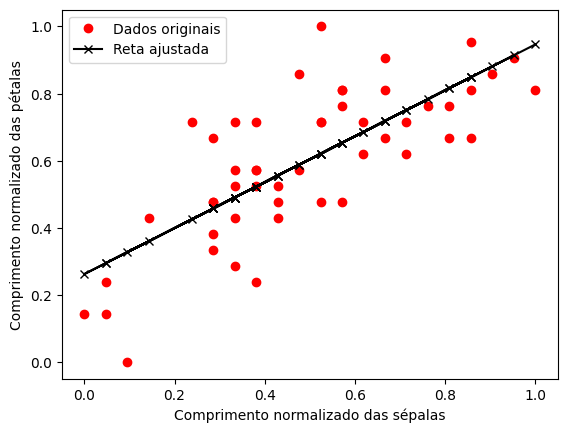

In [35]:
y_pred = model.forward(x_train_bias)
plt.plot(x_train, y_train, 'ro', label='Dados originais')
plt.plot(x_train, y_pred, 'kx-', label='Reta ajustada')
plt.xlabel('Comprimento normalizado das sépalas')
plt.ylabel('Comprimento normalizado das pétalas')
plt.legend()
plt.show()

### Parâmetros treinados

In [36]:
print(model.w)   # [w0 w1]

[[0.26295353 0.68335641]]


### Custo do modelo treinado

In [37]:
loss = np.square(y_pred - y_train).mean()
loss

np.float64(0.02117000379151052)

### Valor ótimo: solução analítica

A regressão linear tem solução exata, dada pela equação normal (o ponto em que $\nabla_{\mathbf{w}} J = 0$):

$$ \mathbf{w}^T = (\mathbf{X}^T \mathbf{X})^{-1} \mathbf{X}^T \mathbf{y} $$

com shapes $(2, 1) = (2, 2) \times (2, M) \times (M, 1)$. O gradiente descendente deve chegar perto desse valor.

In [38]:
x = x_train_bias
y = y_train
w_opt = (np.linalg.inv((x.T).dot(x)).dot(x.T)).dot(y)   # (2, 1)
print(w_opt.T)

[[0.26134159 0.68646976]]


## Exercícios

### Questões

1. Quantos parâmetros são treinados nesse modelo?

R: 2 parâmetros

2. Qual é o número de atributos de entrada para a rede?

R: 2 Atributos

3. Qual é o número de saídas da rede?

R: 1 Saida

4. Suponha que agora você tenha 5 mil amostras para fazer a predição. Qual é o shape da matriz de entrada? Qual é o shape da matriz de saída?

(5000,2). (5000,1)

### Atividades

1. Modifique o laço de treinamento via gradiente descendente para guardar numa lista `losses` o valor do custo no final de cada época. Após o treinamento, plote o custo em função da época.

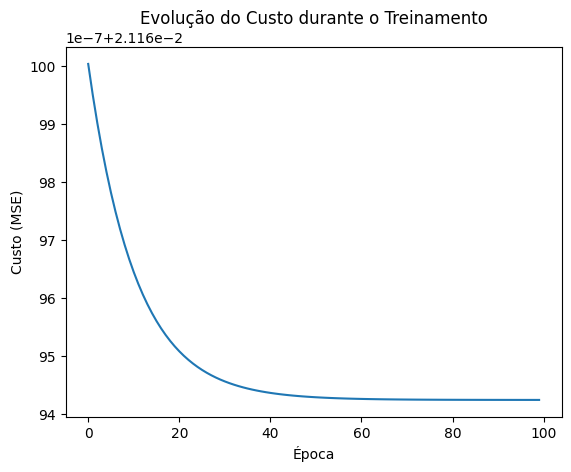

In [39]:
# TODO: escreva sua solução aqui

n_epochs = 100
lr = 0.5
losses = []
for epoch in range(n_epochs):

    # forward - predição
    y_pred = model.forward(x_train_bias)                    # (M, 1)

    # cálculo da função de custo (MSE)
    loss = np.square(y_pred - y_train).mean()

    # cálculo do gradiente pelas derivadas parciais
    w_grad = (2.0 / n_samples) * (x_train_bias.T).dot(y_pred - y_train)   # (2, M) x (M, 1) -> (2, 1)

    # gradiente descendente
    model.w = model.w - lr * w_grad.T                       # (1, 2)
    losses.append(loss)

plt.plot(losses)
plt.xlabel('Época')
plt.ylabel('Custo (MSE)')
plt.title('Evolução do Custo durante o Treinamento')
plt.show()


2. Calcule o valor do custo (MSE) da rede com os parâmetros inicializados, sem treinamento.

In [43]:
# TODO: escreva sua solução aqui
model = Net(2, 1)
y_pred = model.forward(x_train_bias)                    # (M, 1)
loss = np.square(y_pred - y_train).mean()

print("MSE sem treinamento: ", loss)

MSE sem treinamento:  0.4323749322844236


3. Coloque os valores dos pesos da solução analítica no modelo da rede, calcule o valor do custo (MSE) e compare com o custo obtido pelo gradiente descendente.

In [49]:
# TODO: escreva sua solução aqui
model = Net(2, 1)
model.w = w_opt.T
y_pred = model.forward(x_train_bias)                    # (M, 1)
loss = np.square(y_pred - y_train).mean()

print("MSE sem treinamento: ", loss)

MSE sem treinamento:  0.021169424119097165


O modelo sem treinamento apresentou um custo (MSE) mais de 2x maior do que a solução ótima. Já o treinado com gradiente se aproximou bastante do resultado ótimo

## Aprendizados

- A predição de todas as amostras é um produto de matrizes, $\hat{\mathbf{y}} = \mathbf{X}\mathbf{w}^T$, com shapes $(M, 1) = (M, 2) \times (2, 1)$; a coluna de 1s em `x_train_bias` transforma o bias num peso comum.
- O gradiente do MSE é $\nabla_{\mathbf{w}} J = \frac{2}{M}\mathbf{X}^T(\mathbf{X}\mathbf{w}^T - \mathbf{y})$, e cada época faz predição → custo → gradiente → atualização.
- O gradiente descendente chega perto da solução analítica (equação normal) sem inverter nenhuma matriz; isso é o que permite treinar modelos em que não existe solução exata.
- O laço deste notebook é o mesmo que o PyTorch executará nos próximos notebooks: no 2.3 com tensores, no 2.4 com o gradiente calculado automaticamente.